# 08 — Final experiment comparison (Notebook 1 vs Notebook 2 V2)

**Read-only model comparison.** This notebook reads saved test-metric JSON files and the V2 sequence-dataset metadata. It does not train models, rerun inference, change sequence arrays, or overwrite checkpoints.

It normalizes the different metric schemas used by the older LSTM experiments, the V2 ST-GCN-inspired experiment (Notebook 05), and the V2 RGB + pose fusion experiment (Notebook 07). Video-level metrics are compared with video-level metrics; window-level metrics are shown separately.

**Reporting caution:** Notebook 2 uses the recording-group-aware randomized split already stored in the sequence manifest. Do not call it the official UCF101 split unless the source manifest proves that. Results from Notebook 1 are marked as not directly comparable unless their exact test split can be verified.


In [1]:
from pathlib import Path
import json
import math
import warnings
import pandas as pd
import numpy as np

# Project locations on the Windows machine.
PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
NOTEBOOK2_DIR = PROJECT_DIR / "Notebook_2_Improved_v2"
REPORT_DIR = NOTEBOOK2_DIR / "outputs" / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# This pointer is written by Notebook 04. It identifies the exact V2 split used
# to build the full tracked-pose sequence dataset.
SEQUENCE_POINTER = NOTEBOOK2_DIR / "data" / "CURRENT_TRACKED_SEQUENCE_DIR.txt"
CURRENT_SEQUENCE_DIR = None
DATASET_META = {}
if SEQUENCE_POINTER.is_file():
    pointer_text = SEQUENCE_POINTER.read_text(encoding="utf-8").strip()
    if pointer_text:
        CURRENT_SEQUENCE_DIR = Path(pointer_text).resolve()
        metadata_path = CURRENT_SEQUENCE_DIR / "dataset_metadata.json"
        if metadata_path.is_file():
            DATASET_META = json.loads(metadata_path.read_text(encoding="utf-8"))

SEARCH_ROOTS = [
    PROJECT_DIR / "outputs" / "reports",       # Notebook 1 reports
    NOTEBOOK2_DIR / "outputs" / "reports",     # Notebook 2 reports
    NOTEBOOK2_DIR / "outputs" / "models",      # Notebook 2 model-run folders
]

print("Project:", PROJECT_DIR)
print("Notebook 2:", NOTEBOOK2_DIR)
print("Current V2 sequence dataset:", CURRENT_SEQUENCE_DIR)
if DATASET_META:
    print("V2 dataset full:", DATASET_META.get("is_full_dataset"))
    print("V2 windows by split:", DATASET_META.get("windows_by_split"))
    print("Recording-group split reused:", DATASET_META.get("recording_group_split_reused_without_changes"))
else:
    print("Dataset metadata not found from the current pointer. V2 split identity will be marked unverified.")


Project: C:\Users\admin\ViTPose_Action_Recognition
Notebook 2: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2
Current V2 sequence dataset: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\data\sequences_tracked_group_split_iou_v3_full_v1\20261031_035536
V2 dataset full: True
V2 windows by split: {'train': 40404, 'val': 13424, 'test': 14452}
Recording-group split reused: True


## 1. Discover and normalize saved test metrics

The older notebooks and the V2 notebooks use slightly different JSON field names. The next cell reads supported schemas without treating an unqualified `test_accuracy` as video-level accuracy. It prefers **macro-F1 over classes with test support** for the main comparison and keeps all-model-class macro-F1 in a separate column.


In [2]:
def _as_dict(value):
    return value if isinstance(value, dict) else {}

def _first_number(*values):
    for value in values:
        if isinstance(value, (int, float, np.integer, np.floating)) and not isinstance(value, bool):
            if math.isfinite(float(value)):
                return float(value)
    return np.nan

def _first_value(*values):
    for value in values:
        if value is not None and value != "":
            return value
    return None

def _read_json(path):
    try:
        obj = json.loads(path.read_text(encoding="utf-8"))
        return obj if isinstance(obj, dict) else None
    except Exception:
        return None

def _load_run_config(metrics_path):
    # Notebook 05/07 store the training configuration beside test_metrics.json.
    for parent in [metrics_path.parent, *list(metrics_path.parents)[:3]]:
        cfg_path = parent / "worker_config.json"
        if cfg_path.is_file():
            cfg = _read_json(cfg_path)
            if cfg:
                return cfg
    return {}

def _normalize_metrics(path, obj):
    video = _as_dict(obj.get("video_metrics"))
    window = _as_dict(obj.get("window_metrics"))

    # Video-level metrics: nested V2 schema and explicit legacy flat schemas.
    video_accuracy = _first_number(
        video.get("accuracy"),
        obj.get("test_video_accuracy"),
        obj.get("video_level_accuracy"),
        obj.get("test_video_level_accuracy"),
    )
    video_balanced = _first_number(
        video.get("balanced_accuracy"),
        obj.get("test_video_balanced_accuracy"),
        obj.get("video_level_balanced_accuracy"),
    )
    video_f1_supported = _first_number(
        video.get("macro_f1_supported_classes"),
        obj.get("test_video_macro_f1_supported_classes"),
        obj.get("video_level_macro_f1_supported_classes"),
        obj.get("video_level_macro_f1"),
        obj.get("test_video_macro_f1"),
    )
    video_f1_all = _first_number(
        video.get("macro_f1_all_classes"),
        obj.get("test_video_macro_f1_all_classes"),
        obj.get("video_level_macro_f1_all_classes_zero_support_as_zero"),
        obj.get("video_level_macro_f1_all_classes"),
    )

    # Window-level metrics remain separate; never substitute them for video scores.
    window_accuracy = _first_number(
        window.get("accuracy"), obj.get("test_window_accuracy"), obj.get("window_level_accuracy")
    )
    window_balanced = _first_number(
        window.get("balanced_accuracy"), obj.get("test_window_balanced_accuracy"), obj.get("window_level_balanced_accuracy")
    )
    window_f1_supported = _first_number(
        window.get("macro_f1_supported_classes"), obj.get("test_window_macro_f1_supported_classes"), obj.get("window_level_macro_f1_supported_classes")
    )
    window_f1_all = _first_number(
        window.get("macro_f1_all_classes"), obj.get("test_window_macro_f1_all_classes"), obj.get("window_level_macro_f1_all_classes")
    )

    # Older Notebook 1 reports may expose only a generic test_accuracy. Keep it
    # explicitly unclassified; do not quietly compare it to video-level scores.
    unqualified_test_accuracy = _first_number(obj.get("test_accuracy"), obj.get("accuracy"))

    cfg = _load_run_config(path)
    seq_value = _first_value(
        obj.get("sequence_dir"), obj.get("sequence_directory"), obj.get("dataset_dir"),
        cfg.get("sequence_dir"), cfg.get("sequence_directory")
    )
    sequence_dir = None
    if seq_value:
        try:
            sequence_dir = str(Path(str(seq_value)).resolve())
        except Exception:
            sequence_dir = str(seq_value)

    experiment = str(_first_value(obj.get("experiment"), obj.get("model_name"), path.parent.name, path.stem))
    if "fusion" in experiment.lower() or "rgb" in experiment.lower():
        model_family = "RGB + pose fusion"
    elif "st-gcn" in experiment.lower() or "stgcn" in experiment.lower() or "graph" in experiment.lower():
        model_family = "ST-GCN-inspired"
    elif "lstm" in experiment.lower():
        model_family = "LSTM / BiLSTM pose"
    else:
        model_family = "Other / legacy"

    # Determine whether this exact run uses the active Notebook 2 sequence set.
    uses_current_v2_split = False
    if sequence_dir and CURRENT_SEQUENCE_DIR is not None:
        try:
            uses_current_v2_split = Path(sequence_dir).resolve() == CURRENT_SEQUENCE_DIR
        except Exception:
            uses_current_v2_split = sequence_dir == str(CURRENT_SEQUENCE_DIR)

    split_label = (
        "Notebook 2 V2 — current recording-group sequence split"
        if uses_current_v2_split else
        ("Sequence split recorded; not current V2 pointer" if sequence_dir else "Not verified from metrics/config")
    )

    return {
        "experiment": experiment,
        "model_family": model_family,
        "source_notebook": "Notebook 2 V2" if "Notebook_2_Improved_v2" in str(path) else "Notebook 1 / legacy",
        "video_test_accuracy": video_accuracy,
        "video_test_balanced_accuracy": video_balanced,
        "video_test_macro_f1_supported_classes": video_f1_supported,
        "video_test_macro_f1_all_model_classes": video_f1_all,
        "window_test_accuracy": window_accuracy,
        "window_test_balanced_accuracy": window_balanced,
        "window_test_macro_f1_supported_classes": window_f1_supported,
        "window_test_macro_f1_all_model_classes": window_f1_all,
        "unqualified_test_accuracy_not_used_for_video_comparison": unqualified_test_accuracy,
        "test_videos": _first_number(obj.get("test_videos"), obj.get("test_source_videos"), obj.get("test_video_count")),
        "test_windows": _first_number(obj.get("test_windows"), obj.get("test_samples")),
        "test_classes_evaluated": _first_number(obj.get("test_classes_evaluated"), obj.get("classes_with_test_support"), video.get("classes_in_macro_f1")),
        "classes_in_model": _first_number(obj.get("classes_in_model"), obj.get("num_classes")),
        "best_epoch": _first_number(obj.get("best_epoch")),
        "device": _first_value(obj.get("device"), cfg.get("device"), "not recorded"),
        "sequence_dir": sequence_dir or "not recorded",
        "split_label": split_label,
        "uses_current_v2_split": uses_current_v2_split,
        "metrics_file": str(path),
        "checkpoint": _first_value(obj.get("checkpoint"), obj.get("model_path"), "not recorded"),
    }

# Prefer explicit test_metrics*.json files. Also inspect other JSON files under
# Notebook 1 reports, because legacy experiments used several naming schemes.
candidate_paths = []
for root in SEARCH_ROOTS:
    if not root.is_dir():
        continue
    for path in root.rglob("*.json"):
        if path.name.lower() in {"worker_config.json", "dataset_metadata.json", "progress_state.json"}:
            continue
        candidate_paths.append(path)

normalized_rows = []
seen_paths = set()
for path in sorted(candidate_paths):
    try:
        resolved = str(path.resolve())
    except Exception:
        resolved = str(path)
    if resolved in seen_paths:
        continue
    seen_paths.add(resolved)
    obj = _read_json(path)
    if not obj:
        continue
    row = _normalize_metrics(path, obj)
    # Ignore JSON files that contain no actual evaluation metric fields.
    metric_values = [row[k] for k in [
        "video_test_accuracy", "video_test_macro_f1_supported_classes",
        "video_test_macro_f1_all_model_classes", "window_test_accuracy",
        "window_test_macro_f1_supported_classes", "unqualified_test_accuracy_not_used_for_video_comparison"
    ]]
    if any(isinstance(v, (int, float, np.number)) and np.isfinite(v) for v in metric_values):
        normalized_rows.append(row)

comparison = pd.DataFrame(normalized_rows)
if comparison.empty:
    print("No recognized saved test-metrics JSON files were found. Check SEARCH_ROOTS and run the evaluation cells first.")
else:
    comparison = comparison.sort_values(
        ["uses_current_v2_split", "video_test_accuracy"], ascending=[False, False], na_position="last"
    ).reset_index(drop=True)
    print("Recognized evaluation files:", len(comparison))
    display(comparison[[
        "source_notebook", "model_family", "experiment", "video_test_accuracy",
        "video_test_balanced_accuracy", "video_test_macro_f1_supported_classes",
        "video_test_macro_f1_all_model_classes", "test_videos", "test_windows",
        "test_classes_evaluated", "best_epoch", "split_label"
    ]])


Recognized evaluation files: 12


,source_notebook,model_family,experiment,video_test_accuracy,video_test_balanced_accuracy,video_test_macro_f1_supported_classes,video_test_macro_f1_all_model_classes,test_videos,test_windows,test_classes_evaluated,best_epoch,split_label
0,Notebook 2 V2,RGB + pose fusion,late RGB + enriched tracked-pose fusion,0.855893,0.842168,0.834341,NaN,1943.0,14452.0,99.0,12.0,Notebook 2 V2 — current recording-group sequen...
1,Notebook 2 V2,ST-GCN-inspired,ST-GCN-inspired model on full tracked UCF101 p...,0.530108,0.464861,0.447064,NaN,1943.0,14452.0,NaN,42.0,Notebook 2 V2 — current recording-group sequen...
2,Notebook 1 / legacy,Other / legacy,reports,0.701762,0.672062,0.670482,NaN,2441.0,21009.0,NaN,2.0,Not verified from metrics/config
3,Notebook 1 / legacy,Other / legacy,reports,0.666530,0.635147,0.626836,NaN,2441.0,21009.0,NaN,18.0,Not verified from metrics/config
4,Notebook 1 / legacy,Other / legacy,reports,0.661614,0.630565,0.622157,NaN,2441.0,21009.0,NaN,11.0,Not verified from metrics/config
5,Notebook 1 / legacy,Other / legacy,reports,0.655879,0.625869,0.621053,NaN,2441.0,21009.0,NaN,39.0,Not verified from metrics/config
6,Notebook 1 / legacy,LSTM / BiLSTM pose,BiLSTM + temporal attention on group-aware ran...,0.505544,NaN,NaN,NaN,2435.0,21960.0,100.0,11.0,Not verified from metrics/config
7,Notebook 1 / legacy,Other / legacy,reports,NaN,NaN,NaN,NaN,7.0,50.0,NaN,9.0,Not verified from metrics/config
8,Notebook 1 / legacy,Other / legacy,reports,NaN,NaN,NaN,NaN,NaN,21009.0,NaN,17.0,Not verified from metrics/config
9,Notebook 1 / legacy,Other / legacy,reports,NaN,NaN,NaN,NaN,NaN,21009.0,NaN,2.0,Not verified from metrics/config


## 2. Check which experiments are directly comparable

The V2 ST-GCN and RGB + pose fusion experiments should use the same current sequence directory. The following cell checks the recorded `worker_config.json` files and test counts. If the sequence path is identical, the runs share the same saved train/validation/test window assignments. Older Notebook 1 results are not declared comparable unless their split is explicitly identified.


In [3]:
# Summarize the current V2 runs and whether their split source matches.
v2 = comparison[comparison["uses_current_v2_split"] == True].copy() if not comparison.empty else pd.DataFrame()

print("Current V2 sequence directory:", CURRENT_SEQUENCE_DIR)
if not v2.empty:
    print("V2 evaluation runs using this sequence directory:", len(v2))
    display(v2[["model_family", "experiment", "video_test_accuracy",
                "video_test_macro_f1_supported_classes", "test_videos", "test_windows",
                "sequence_dir", "metrics_file"]])

    # Specifically compare ST-GCN-inspired and RGB+pose fusion if both exist.
    stgcn_rows = v2[v2["model_family"].eq("ST-GCN-inspired")]
    fusion_rows = v2[v2["model_family"].eq("RGB + pose fusion")]
    if not stgcn_rows.empty and not fusion_rows.empty:
        stg = stgcn_rows.iloc[0]
        fus = fusion_rows.iloc[0]
        same_sequence_dir = stg["sequence_dir"] == fus["sequence_dir"]
        same_test_counts = (
            pd.notna(stg["test_videos"]) and pd.notna(fus["test_videos"]) and
            pd.notna(stg["test_windows"]) and pd.notna(fus["test_windows"]) and
            int(stg["test_videos"]) == int(fus["test_videos"]) and
            int(stg["test_windows"]) == int(fus["test_windows"])
        )
        print("\nST-GCN vs RGB + pose fusion checks")
        print("Same sequence directory:", same_sequence_dir)
        print("Same test video/window counts:", same_test_counts)
        print("ST-GCN test videos/windows:", stg["test_videos"], "/", stg["test_windows"])
        print("Fusion test videos/windows:", fus["test_videos"], "/", fus["test_windows"])
        if same_sequence_dir and same_test_counts:
            print("Conclusion: the saved configurations and counts support a same-split V2 comparison.")
        else:
            print("WARNING: same test split could not be fully verified from paths and counts; qualify the comparison.")
    else:
        print("Both V2 ST-GCN and RGB+pose metrics were not found. Check that both final test_metrics.json files exist.")
else:
    print("No metrics file was tied to the current V2 sequence directory. Review worker_config.json files and metric paths.")

# Dataset support warnings from Notebook 04 metadata.
if DATASET_META:
    for key, label in [
        ("classes_without_train_windows", "Classes without training windows"),
        ("classes_without_val_windows", "Classes without validation windows"),
        ("classes_without_test_windows", "Classes without test windows"),
    ]:
        print(f"{label}:", DATASET_META.get(key, []))


Current V2 sequence directory: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\data\sequences_tracked_group_split_iou_v3_full_v1\20261031_035536
V2 evaluation runs using this sequence directory: 2


,model_family,experiment,video_test_accuracy,video_test_macro_f1_supported_classes,test_videos,test_windows,sequence_dir,metrics_file
0,RGB + pose fusion,late RGB + enriched tracked-pose fusion,0.855893,0.834341,1943.0,14452.0,C:\Users\admin\ViTPose_Action_Recognition\Note...,C:\Users\admin\ViTPose_Action_Recognition\Note...
1,ST-GCN-inspired,ST-GCN-inspired model on full tracked UCF101 p...,0.530108,0.447064,1943.0,14452.0,C:\Users\admin\ViTPose_Action_Recognition\Note...,C:\Users\admin\ViTPose_Action_Recognition\Note...



ST-GCN vs RGB + pose fusion checks
Same sequence directory: True
Same test video/window counts: True
ST-GCN test videos/windows: 1943.0 / 14452.0
Fusion test videos/windows: 1943.0 / 14452.0
Conclusion: the saved configurations and counts support a same-split V2 comparison.
Classes without training windows: ['BreastStroke']
Classes without validation windows: ['BreastStroke', 'FrontCrawl']
Classes without test windows: ['BreastStroke', 'CliffDiving']


## 3. Save comparison tables and plots

The main chart below compares **video-level accuracy** and **video-level supported-class macro-F1** only. Window-level metrics are saved separately and are not mixed into the video-level chart. The CSV retains file paths, split-verification flags, class counts and both supported-class/all-model-class macro-F1 values for auditability.


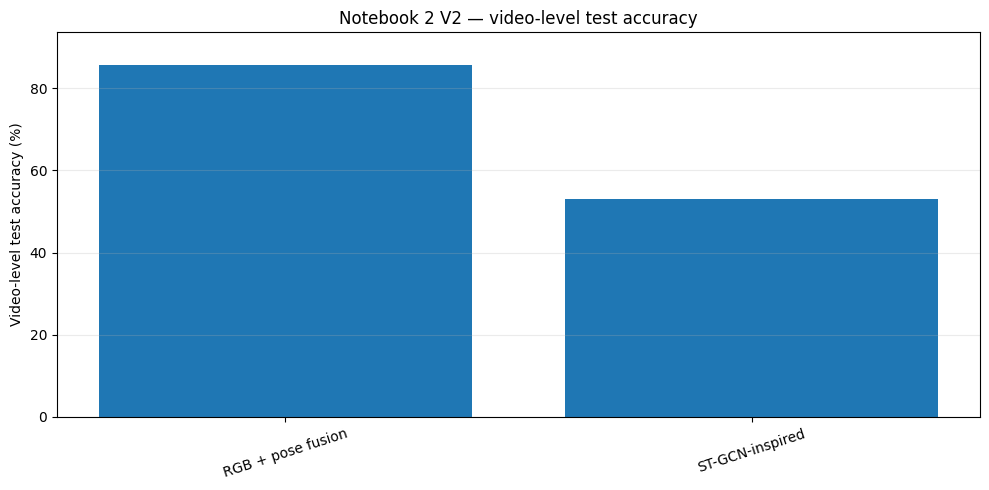

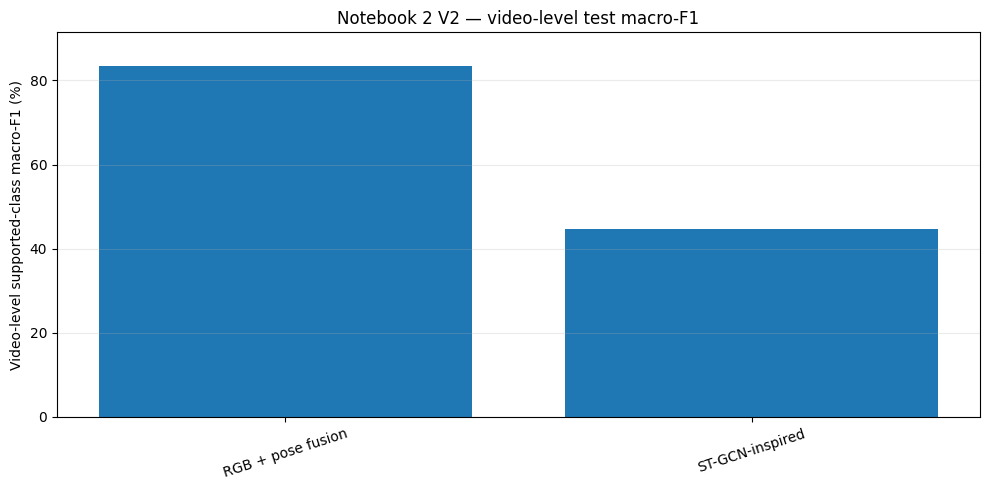

Saved video-level comparison: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\reports\experiment_comparison_v2.csv
Saved window-level comparison: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\reports\experiment_comparison_v2_window_metrics.csv
Saved plot: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\reports\experiment_comparison_v2_video_accuracy.png
Saved plot: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\reports\experiment_comparison_v2_video_macro_f1.png


In [4]:
if comparison.empty:
    print("No comparison table or plot created because no test metrics were discovered.")
else:
    csv_path = REPORT_DIR / "experiment_comparison_v2.csv"
    comparison.to_csv(csv_path, index=False)

    # Restrict the headline V2 comparison plot to models using the active V2 split.
    # Notebook 1 results can still appear in the CSV, but are not plotted as directly comparable
    # unless their exact split is independently confirmed.
    plot_df = comparison[
        comparison["uses_current_v2_split"] & comparison["video_test_accuracy"].notna()
    ].copy()

    plot_paths = []
    if not plot_df.empty:
        import matplotlib.pyplot as plt
        short_names = [
            ("RGB + pose fusion" if r == "RGB + pose fusion" else
             "ST-GCN-inspired" if r == "ST-GCN-inspired" else
             str(exp)[:34])
            for r, exp in zip(plot_df["model_family"], plot_df["experiment"])
        ]

        fig, ax = plt.subplots(figsize=(10, 5))
        vals = plot_df["video_test_accuracy"].astype(float).to_numpy() * 100
        ax.bar(short_names, vals)
        ax.set_ylabel("Video-level test accuracy (%)")
        ax.set_title("Notebook 2 V2 — video-level test accuracy")
        ax.set_ylim(0, min(100, max(10, float(np.nanmax(vals)) + 8)))
        ax.tick_params(axis="x", rotation=18)
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        p = REPORT_DIR / "experiment_comparison_v2_video_accuracy.png"
        fig.savefig(p, dpi=160)
        plt.show()
        plt.close(fig)
        plot_paths.append(p)

        f1_df = plot_df[plot_df["video_test_macro_f1_supported_classes"].notna()].copy()
        if not f1_df.empty:
            f1_names = [
                ("RGB + pose fusion" if r == "RGB + pose fusion" else
                 "ST-GCN-inspired" if r == "ST-GCN-inspired" else str(exp)[:34])
                for r, exp in zip(f1_df["model_family"], f1_df["experiment"])
            ]
            fig, ax = plt.subplots(figsize=(10, 5))
            f1_vals = f1_df["video_test_macro_f1_supported_classes"].astype(float).to_numpy() * 100
            ax.bar(f1_names, f1_vals)
            ax.set_ylabel("Video-level supported-class macro-F1 (%)")
            ax.set_title("Notebook 2 V2 — video-level test macro-F1")
            ax.set_ylim(0, min(100, max(10, float(np.nanmax(f1_vals)) + 8)))
            ax.tick_params(axis="x", rotation=18)
            ax.grid(axis="y", alpha=0.25)
            fig.tight_layout()
            p = REPORT_DIR / "experiment_comparison_v2_video_macro_f1.png"
            fig.savefig(p, dpi=160)
            plt.show()
            plt.close(fig)
            plot_paths.append(p)
    else:
        print("No results tied to the current V2 split, so no direct-comparison chart was created.")

    # A compact separate table for window-level metrics.
    window_cols = [
        "source_notebook", "model_family", "experiment", "window_test_accuracy",
        "window_test_balanced_accuracy", "window_test_macro_f1_supported_classes",
        "window_test_macro_f1_all_model_classes", "test_windows", "metrics_file"
    ]
    window_table = comparison[[c for c in window_cols if c in comparison.columns]].copy()
    window_csv = REPORT_DIR / "experiment_comparison_v2_window_metrics.csv"
    window_table.to_csv(window_csv, index=False)

    print("Saved video-level comparison:", csv_path)
    print("Saved window-level comparison:", window_csv)
    for p in plot_paths:
        print("Saved plot:", p)


## 4. Interpretation and reporting rules

- Use **video-level test accuracy** as the headline accuracy when comparing video-level action recognition.
- Report **video-level macro-F1 over supported test classes** and the number of supported classes. Keep all-model-class macro-F1 separate because classes absent from the test set receive zero support.
- Do not compare window accuracy with video accuracy.
- Notebook 2 V2 results are directly comparable only when they use the same sequence directory / test split. This notebook checks the saved run configurations and test counts.
- Notebook 1 results are labelled as split-unverified unless their source metric metadata proves the same test split. Do not claim a fair apples-to-apples comparison otherwise.
- The V2 split is recording-group-aware and randomized according to the saved manifest; it is not automatically the official UCF101 split protocol.
- Notebook 04 reported classes with zero windows in particular splits. Keep those limitations in the project report.
- The comparison notebook is a reporting tool. It does not alter model weights, feature files, sequence arrays, or training results.
